# Per-point curvature errors along the normalized arc length (SI Section 6.3, Fig. S11)

3D error (Euclidean distance between predicted and reference backbone points) of the constant, affine and quadratic curvature CNNs at each reference point, on the test set;
markers show the median and error bars the interquartile range.
(a) Single-section arm: points at $L/3$, $2L/3$ and $L$, reference fitted to motion capture.
(b) Multi-section arm: points every ninth of the manipulator length, model-constrained reference generated by $N_C$.

**Inputs** (repository): `../SINGLE/results/revision_single_test.npz` and `results/revision_multi_test.npz`, the per-sample test errors written by
`SINGLE_revision_figures.ipynb` and `MULTI_revision_figures.ipynb` (original 85/10/5 split, 500 test samples per arm).
**Output**: `results/figS11_per_point.pdf`. Run from inside `MULTI/`.

In [1]:
import shutil
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({
    "font.family": "serif", "font.size": 13, "axes.labelsize": 14, "xtick.labelsize": 12, "ytick.labelsize": 12,
    "legend.fontsize": 12, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": "gray", "grid.linewidth": 0.5, "grid.alpha": 0.3,
    "text.usetex": shutil.which("latex") is not None, "mathtext.fontset": "cm",
})

MODELS = [("const", "Constant", "tab:red", "s"), ("affine", "Affine", "tab:green", "^"), ("quad", "Quadratic", "tab:blue", "o")]
single = np.load("../SINGLE/results/revision_single_test.npz")
multi = np.load("results/revision_multi_test.npz")

## Fig. S11

Single Constant  median per point [mm]: [0.56 1.9  3.93]
Single Affine    median per point [mm]: [0.59 1.9  4.  ]
Single Quadratic median per point [mm]: [0.61 2.01 4.15]
Multi  Constant  median per point [mm]: [ 0.75  2.61  5.77  9.61 14.42 20.24 26.89 34.16 41.46]
Multi  Affine    median per point [mm]: [ 0.72  2.5   5.38  9.15 13.68 19.74 26.16 32.76 40.77]
Multi  Quadratic median per point [mm]: [ 0.68  2.54  5.6   9.54 14.15 20.34 26.12 33.34 40.7 ]


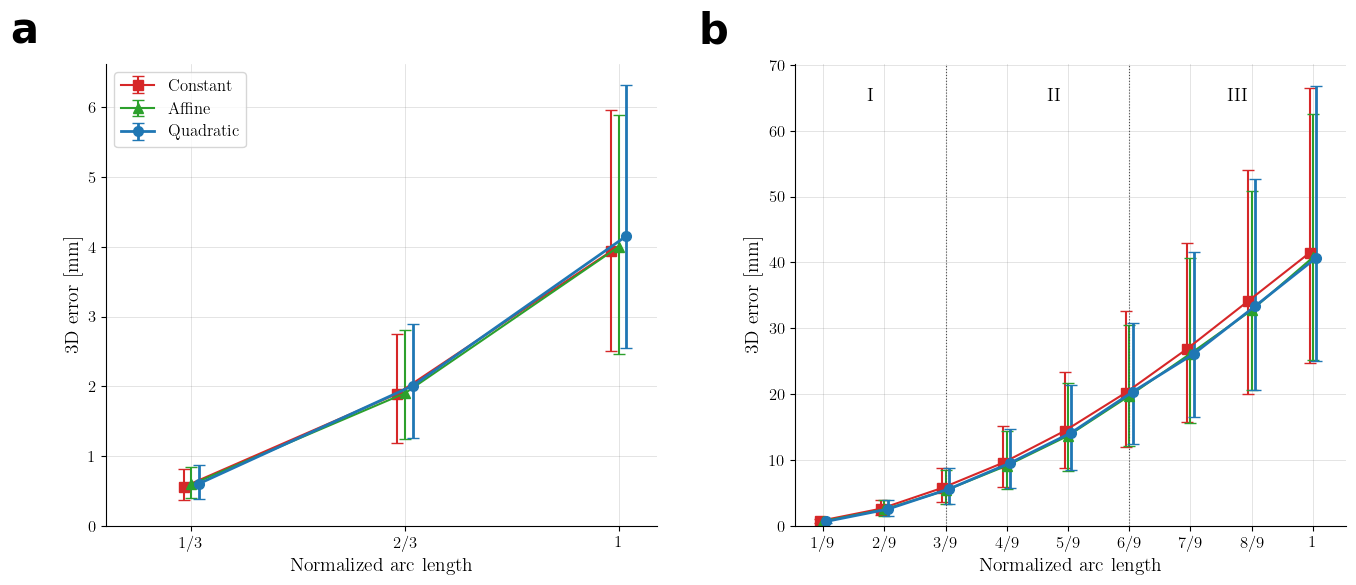

Saved results/figS11_per_point.pdf


In [2]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6), gridspec_kw={"wspace": 0.25})
for ax, D, n, letter in [(axes[0], single, 3, "a"), (axes[1], multi, 9, "b")]:
    x = np.arange(1, n + 1) / n
    dx = 0.012 if n == 3 else 0.006
    for k, (m, label, color, marker) in enumerate(MODELS):
        e = D[f"{m}_vs_label"]
        med, q1, q3 = np.median(e, 0), np.percentile(e, 25, 0), np.percentile(e, 75, 0)
        ax.errorbar(x + (k - 1) * dx, med, yerr=[med - q1, q3 - med], fmt=marker + "-", color=color, ms=7,
                    lw=2 if m == "quad" else 1.5, capsize=4, label=label)
        print(f"{'Single' if n == 3 else 'Multi '} {label:9s} median per point [mm]: {np.round(med, 2)}")
    ax.set_xticks(x, [r"$1$" if i == n else rf"${i}/{n}$" for i in range(1, n + 1)])
    ax.set_xlim(0.2 if n == 3 else 0.06, 1.06)
    ax.set_ylim(bottom=0)
    ax.set_xlabel("Normalized arc length")
    ax.set_ylabel("3D error [mm]")
    if n == 9:
        for b in (3 / 9, 6 / 9):
            ax.axvline(b, color="0.3", lw=0.8, ls=":")
        for xc, sec in zip((1.5 / 9 + 0.03, 4.5 / 9 + 0.03, 7.5 / 9 + 0.03), ("I", "II", "III")):
            ax.text(xc, 0.95, sec, transform=ax.get_xaxis_transform(), ha="center", va="top", fontsize=14)
    fig.text(ax.get_position().x0 - 0.06, 0.97, letter, fontsize=30, fontweight="bold", family="sans-serif", usetex=False, va="top")
axes[0].legend(loc="upper left", frameon=True)
fig.savefig("results/figS11_per_point.pdf", bbox_inches="tight")
plt.show()
print("Saved results/figS11_per_point.pdf")